# FASE 3. DESARROLLO DEL NÚCLEO ALGORÍTMICO, EFICIENCIA Y PROGRAMACIÓN ORIENTADA A OBJETOS

**Magíster en Ciencia de Datos e Inteligencia Artificial**

**Asignatura:** Programación para la Ciencia de Datos (MCDI500)

**Grupo:** 7

**Integrantes:**
- Jairo Barraza Salazar
- Javier Huamanni Barrera
- Jean Salas Meneses
- Pavel Chávez San Martín

**Docente:** Dr. Omar Salinas Silva

## 1. Introducción y objetivos de la Fase 3

### 1.1. Introducción

La Fase 3 del proyecto tiene como propósito implementar un núcleo algorítmico eficiente, modular y orientado a objetos que permita procesar y analizar la exposición operacional documentada a fallas del Sistema Eléctrico Nacional (SEN) en las 15 comunas más pobladas de Chile, conforme a los resultados del Censo 2024.

En la Fase 1 se estableció la problemática de investigación, su alcance territorial, las fuentes de información y la metodología general. Posteriormente, en la Fase 2 se desarrollaron procedimientos de exploración, normalización, integración territorial, caracterización operacional y validación técnica de los informes del Coordinador Eléctrico Nacional (CEN).

El procesamiento previo permitió identificar 18.019 informes consolidados, 23.284 asociaciones territoriales homologadas y 1.834 informes distintos vinculados mediante 1.915 asociaciones con las 15 comunas seleccionadas.

A partir de estos antecedentes, la Fase 3 se concentrará en transformar las operaciones previamente desarrolladas en componentes de software reutilizables, aplicando programación estructurada, recursividad, análisis de eficiencia y programación orientada a objetos.

Se evaluarán diferentes implementaciones algorítmicas, considerando su rendimiento temporal y espacial, la equivalencia de sus resultados y las posibilidades de escalabilidad.

Los indicadores permitirán comparar frecuencias documentales normalizadas, categorías de consumo reportadas, recurrencia de causas e intervalos temporales disponibles. Estas mediciones no representan directamente interrupciones efectivas del suministro, clientes afectados ni indicadores regulatorios SAIDI o SAIFI.

### 1.2. Objetivo general

**Implementar un núcleo algorítmico eficiente, modular y orientado a objetos para procesar y caracterizar la exposición operacional documentada a fallas del Sistema Eléctrico Nacional en las 15 comunas más pobladas de Chile, utilizando los conjuntos de datos validados en F2 y aplicando procedimientos reproducibles de programación, optimización y verificación técnica.**

### 1.3. Objetivos específicos

**OE1. Estructurar** una arquitectura modular para integrar los datos territoriales, temporales y operacionales procesados en F2.

**OE2. Implementar** algoritmos mediante programación estructurada y recursiva para resolver operaciones relacionadas con la información del proyecto.

**OE3. Comparar** la eficiencia de diferentes implementaciones mediante mediciones reproducibles de tiempo de ejecución, memoria y análisis de complejidad algorítmica.

**OE4. Desarrollar** componentes orientados a objetos, aplicando encapsulamiento, herencia y polimorfismo en la gestión y el análisis de los datos.

**OE5. Validar** el núcleo algorítmico mediante pruebas funcionales, casos límite, tratamiento de excepciones y verificaciones de integridad de resultados.

### 1.4. Alcance de la Fase 3

La implementación utilizará como entrada principal los conjuntos procesados y validados en F2.

Se conservará la distinción entre informes únicos y asociaciones documentales informe–comuna, evitando duplicaciones en el cálculo de indicadores.

El procesamiento permitirá comparar los registros mediante denominadores explícitos y criterios de elegibilidad, considerando la población censada y el período de observación.

Se desarrollarán algoritmos equivalentes para contrastar distintas estrategias computacionales y justificar la elección de las implementaciones más apropiadas.

El producto principal será un notebook ejecutable, respaldado por módulos Python reutilizables, pruebas técnicas y documentación del repositorio GitHub.

### 1.5. Resultados esperados

Al finalizar F3 se espera disponer de:

1. Una arquitectura de software modular y documentada.
2. Algoritmos estructurados y recursivos aplicados al proyecto.
3. Comparaciones reproducibles de eficiencia temporal y espacial.
4. Clases y métodos orientados a objetos.
5. Un núcleo integrado capaz de generar indicadores territoriales documentales.
6. Pruebas técnicas que acrediten el funcionamiento del sistema.
7. Un notebook reproducible y un repositorio actualizado con las evidencias del desarrollo.

## 2. Arquitectura inicial y datos de entrada

### 2.1. Continuidad del procesamiento desde F2

El núcleo algorítmico de F3 utilizará los archivos generados durante la etapa de exportación y validación de F2.

La utilización de conjuntos previamente procesados permitirá separar las responsabilidades de preparación de información y desarrollo algorítmico.

Se emplearán tres archivos principales:

| Archivo | Unidad de análisis | Propósito |
|---|---|---|
| `03_cen_informes_prioritarios.csv` | Informe CEN único | Conservar el universo documental de las 15 comunas. |
| `04_cen_fallas_comunas_integrado.csv` | Asociación informe–comuna | Disponer de variables técnicas, territoriales y operacionales. |
| `05_cen_perfiles_15_comunas.csv` | Comuna oficial | Disponer de población y características territoriales. |

Los conjuntos provienen de la carpeta `data/processed/f2` y corresponden a resultados derivados de las fuentes CEN e INE.

### 2.2. Principios de diseño

La arquitectura del sistema se desarrollará considerando los siguientes principios:

**Modularidad:** separación de las funciones de carga, transformación, análisis y validación.

**Cohesión:** cada componente tendrá una responsabilidad funcional claramente definida.

**Bajo acoplamiento:** se limitarán las dependencias entre componentes mediante interfaces y parámetros explícitos.

**Reutilización:** las operaciones podrán utilizarse en distintos conjuntos de datos compatibles.

**Eficiencia:** se evaluarán diferentes estrategias algorítmicas antes de seleccionar la implementación definitiva.

**Trazabilidad:** las entradas, transformaciones y resultados se documentarán mediante código, pruebas y evidencias reproducibles.

### 2.3. Validación inicial de las fuentes

Antes de implementar los algoritmos se comprobará la existencia, integridad y compatibilidad de los archivos procesados.

La verificación incluirá las dimensiones de los conjuntos, disponibilidad de columnas relevantes, unicidad de claves y conservación de asociaciones territoriales.

Los resultados constituirán la línea base para las pruebas y comparaciones posteriores de F3.

In [2]:
# ==========================================================
# FASE 3 - APARTADO 2
# ARQUITECTURA INICIAL Y DATOS DE ENTRADA
# PROYECTO MCDI500 - GRUPO 7
# ==========================================================

from pathlib import Path
import pandas as pd

from IPython.display import display

# ==========================================================
# 1. LOCALIZAR EL PROYECTO
# ==========================================================

def localizar_proyecto(ruta_inicial):
    """
    Identifica la raíz del proyecto MCDI500.
    """

    inicio = Path(ruta_inicial).resolve()

    for carpeta in [inicio, *inicio.parents]:

        if all(
            (carpeta / nombre).is_dir()
            for nombre in ["F1", "F2", "data"]
        ):
            return carpeta

    raise FileNotFoundError(
        "No se encontró la raíz de Proyecto_MCDI500."
    )

RAIZ_F3 = localizar_proyecto(Path.cwd())

CARPETA_DATOS = (
    RAIZ_F3 / "data" / "processed" / "f2"
)

# ==========================================================
# 2. DEFINIR LOS ARCHIVOS DE F2
# ==========================================================

ARCHIVOS_F3 = {
    "informes":
        "03_cen_informes_prioritarios.csv",

    "asociaciones":
        "04_cen_fallas_comunas_integrado.csv",

    "comunas":
        "05_cen_perfiles_15_comunas.csv"
}

# ==========================================================
# 3. FUNCIÓN DE CARGA
# ==========================================================

def cargar_csv_f3(ruta):
    """
    Carga un CSV conservando los identificadores
    documentales y territoriales como texto.
    """

    if not ruta.is_file():
        raise FileNotFoundError(
            f"No se encontró el archivo: {ruta}"
        )

    encabezado = pd.read_csv(
        ruta,
        encoding="utf-8-sig",
        nrows=0
    )

    tipos = {
        columna: "string"
        for columna in ["id_falla", "codigo_comuna"]
        if columna in encabezado.columns
    }

    return pd.read_csv(
        ruta,
        encoding="utf-8-sig",
        dtype=tipos,
        low_memory=False
    )

# ==========================================================
# 4. CARGAR LOS CONJUNTOS
# ==========================================================

df_f3_informes = cargar_csv_f3(
    CARPETA_DATOS / ARCHIVOS_F3["informes"]
)

df_f3_asociaciones = cargar_csv_f3(
    CARPETA_DATOS / ARCHIVOS_F3["asociaciones"]
)

df_f3_comunas = cargar_csv_f3(
    CARPETA_DATOS / ARCHIVOS_F3["comunas"]
)

# ==========================================================
# 5. VALIDAR COLUMNAS REQUERIDAS
# ==========================================================

COLUMNAS_F3 = {
    "informes": {
        "id_falla",
        "estado_normalizado"
    },

    "asociaciones": {
        "id_falla",
        "codigo_comuna",
        "comuna_oficial",
        "estado_normalizado",
        "consumo_normalizado",
        "descripcion_causa"
    },

    "comunas": {
        "codigo_comuna",
        "comuna_oficial",
        "poblacion_2024"
    }
}

CONJUNTOS_F3 = {
    "informes": df_f3_informes,
    "asociaciones": df_f3_asociaciones,
    "comunas": df_f3_comunas
}

for nombre, df in CONJUNTOS_F3.items():

    faltantes = (
        COLUMNAS_F3[nombre] - set(df.columns)
    )

    if faltantes:
        raise ValueError(
            f"Columnas faltantes en {nombre}: "
            f"{sorted(faltantes)}"
        )

# ==========================================================
# 6. VALIDAR INTEGRIDAD
# ==========================================================

assert len(df_f3_informes) == 1834, (
    "El universo de informes F2 no coincide."
)

assert len(df_f3_asociaciones) == 1915, (
    "Las asociaciones F2 no coinciden."
)

assert len(df_f3_comunas) == 15, (
    "La selección comunal no contiene 15 comunas."
)

assert df_f3_informes["id_falla"].is_unique

assert df_f3_comunas["codigo_comuna"].is_unique

assert not df_f3_asociaciones.duplicated(
    subset=["id_falla", "codigo_comuna"]
).any()

assert (
    set(df_f3_asociaciones["id_falla"])
    ==
    set(df_f3_informes["id_falla"])
), (
    "Los identificadores no corresponden "
    "al universo prioritario."
)

assert (
    set(df_f3_asociaciones["codigo_comuna"])
    ==
    set(df_f3_comunas["codigo_comuna"])
), (
    "Existen códigos comunales inconsistentes."
)

# ==========================================================
# 7. VALIDAR POBLACIÓN CENSADA
# ==========================================================

df_f3_comunas["poblacion_2024"] = pd.to_numeric(
    df_f3_comunas["poblacion_2024"],
    errors="coerce"
)

assert df_f3_comunas[
    "poblacion_2024"
].notna().all()

assert df_f3_comunas[
    "poblacion_2024"
].gt(0).all()

# ==========================================================
# 8. PRESENTAR RESULTADOS
# ==========================================================

print("=" * 65)
print("FASE 3 - CARGA Y VALIDACIÓN DE DATOS")
print("=" * 65)

print("\nDirectorio del proyecto:")
print(RAIZ_F3)

resumen_f3 = pd.DataFrame([
    {
        "Conjunto": nombre,
        "Registros": len(df),
        "Variables": len(df.columns),
        "Estado": "VALIDADO"
    }
    for nombre, df in CONJUNTOS_F3.items()
])

print("\nCONJUNTOS DE ENTRADA")

display(resumen_f3)

print("\nCOMUNAS DE ANÁLISIS")

display(
    df_f3_comunas[
        [
            "comuna_oficial",
            "poblacion_2024"
        ]
    ].head(15)
)

print("\n[OK] Informes únicos conservados.")
print("[OK] Asociaciones territoriales conservadas.")
print("[OK] Códigos comunales verificados.")
print("[OK] Población oficial disponible.")
print("[OK] Datos preparados para el núcleo algorítmico.")

FASE 3 - CARGA Y VALIDACIÓN DE DATOS

Directorio del proyecto:
C:\Users\jeanp\OneDrive\00. MAGISTER CIA\M1_Programación para la Ciencia de Datos\Proyecto_MCDI500

CONJUNTOS DE ENTRADA


,Conjunto,Registros,Variables,Estado
0,informes,1834,51,VALIDADO
1,asociaciones,1915,41,VALIDADO
2,comunas,15,20,VALIDADO



COMUNAS DE ANÁLISIS


,comuna_oficial,poblacion_2024
0,Puente Alto,568086.0
1,Maipú,503635.0
2,Santiago,438856.0
3,Antofagasta,401096.0
4,La Florida,374836.0
5,Viña del Mar,334871.0
6,San Bernardo,306371.0
7,Las Condes,296134.0
8,Temuco,292518.0
9,Valparaíso,284938.0



[OK] Informes únicos conservados.
[OK] Asociaciones territoriales conservadas.
[OK] Códigos comunales verificados.
[OK] Población oficial disponible.
[OK] Datos preparados para el núcleo algorítmico.


### 2.4. Diseño funcional de la arquitectura algorítmica

La arquitectura del núcleo algorítmico se diseñará a partir de las operaciones desarrolladas durante F2, incorporando criterios de modularidad, eficiencia, reutilización y programación orientada a objetos.

El sistema tendrá como finalidad procesar los conjuntos de datos preparados y validados, permitiendo caracterizar la exposición operacional documentada a fallas del Sistema Eléctrico Nacional en las 15 comunas más pobladas de Chile.

A diferencia de F2, donde las transformaciones se desarrollaron principalmente mediante programación estructurada y operaciones con Pandas, en F3 estas funcionalidades se organizarán progresivamente en componentes independientes.

#### 2.4.1. Componentes funcionales

Se propone la siguiente arquitectura:

| Componente | Responsabilidad | Resultado |
|---|---|---|
| `FuenteDatos` | Definir una interfaz común para la lectura y validación de conjuntos de datos. | Datos disponibles y verificados. |
| `FuenteCEN` | Gestionar los informes y asociaciones documentales provenientes del CEN. | Registros técnicos y operacionales. |
| `FuenteComunal` | Gestionar la información demográfica y territorial del INE. | Maestro de las 15 comunas. |
| `AnalizadorExposicion` | Calcular frecuencias documentales absolutas y normalizadas. | Indicadores comparativos por comuna. |
| `AnalizadorRecurrencia` | Identificar las descripciones causales más frecuentes y su distribución territorial. | Perfiles de recurrencia documental. |
| `AnalizadorDuracion` | Procesar intervalos documentales válidos y calcular estadísticas temporales. | Indicadores de duración documental. |
| `ValidadorResultados` | Comprobar la integridad, coherencia y consistencia de los resultados. | Evidencia de validación técnica. |

#### 2.4.2. Integración de las dimensiones de análisis

El núcleo algorítmico incorporará tres dimensiones analíticas complementarias.

**Frecuencia documental**

Se utilizará la cantidad de informes asociados con cada comuna, considerando criterios explícitos de inclusión y exclusión de registros.

Para facilitar las comparaciones territoriales, se calcularán indicadores normalizados por población censada y período observado.

**Recurrencia causal**

Se identificarán las descripciones de fallas más frecuentes entre los informes, distinguiendo las categorías con causas específicas de aquellas que presentan información causal no determinada.

Se conservará la diferencia entre causas presuntas y definitivas.

**Duración documental**

Se utilizarán las fechas de perturbación y término registradas por el CEN para analizar los intervalos temporales válidos.

Se considerarán únicamente informes finalizados que dispongan de fechas válidas y presenten intervalos no negativos.

Los informes pendientes y anulados se conservarán en el universo documental, pero no participarán en el cálculo principal de duración.

Las estadísticas temporales incluirán cantidad de informes válidos, mediana, percentil 75 y distribución de intervalos.

La mediana se utilizará como indicador descriptivo principal, debido a la presencia de valores extremos identificados durante F2.

#### 2.4.3. Principios de programación orientada a objetos

La arquitectura permitirá aplicar progresivamente los siguientes principios:

**Abstracción:** definición de una interfaz común para gestionar las fuentes de información.

**Encapsulamiento:** protección de los atributos internos y configuración de los componentes.

**Herencia:** especialización de las clases encargadas de gestionar distintas fuentes de datos.

**Polimorfismo:** utilización de métodos comunes con implementaciones específicas según el tipo de fuente.

**Composición:** integración de analizadores independientes dentro del núcleo algorítmico.

La implementación se desarrollará procurando alta cohesión y bajo acoplamiento, evitando dependencias innecesarias entre componentes.

#### 2.4.4. Estrategia de eficiencia

Se compararán diferentes estrategias de procesamiento para operaciones representativas del proyecto.

Particularmente, se utilizará la búsqueda y asociación territorial como caso de estudio para contrastar implementaciones secuenciales, estructuras de consulta mediante diccionarios y operaciones de integración con Pandas.

Asimismo, se evaluarán funciones de agregación temporal y procedimientos de recorrido de estructuras jerárquicas mediante programación iterativa y recursiva.

Las comparaciones considerarán equivalencia de resultados, tiempos de ejecución, utilización de memoria y complejidad algorítmica.

#### 2.4.5. Flujo funcional del sistema

El procesamiento seguirá la siguiente secuencia:

**Datos F2 → Validación de entradas → Gestión de fuentes → Análisis de frecuencia, recurrencia y duración → Integración territorial → Validación de resultados → Presentación de indicadores.**

Esta organización permitirá mantener la trazabilidad entre los resultados obtenidos en F2 y las funcionalidades implementadas durante F3.

La arquitectura propuesta se utilizará como referencia para desarrollar los algoritmos, clases y pruebas de los siguientes apartados.

### 2.5. Diagnóstico de las variables temporales de entrada

La dimensión temporal constituye un componente relevante para caracterizar los antecedentes operacionales documentados en los informes del Coordinador Eléctrico Nacional.

Durante F2 se construyeron variables derivadas de las fechas de perturbación y término, permitiendo identificar intervalos documentales y clasificar su validez.

En esta etapa se verificará que dichas variables estén disponibles en los archivos procesados que utilizará F3.

#### 2.5.1. Variables consideradas

| Variable | Descripción |
|---|---|
| `id_falla` | Identificador único del informe. |
| `estado_normalizado` | Estado administrativo del informe. |
| `fecha_perturbacion_dt` | Fecha y hora de perturbación procesada. |
| `fecha_termino_dt` | Fecha y hora de término procesada. |
| `intervalo_documental_horas` | Diferencia temporal expresada en horas. |
| `validacion_temporal` | Clasificación de consistencia temporal. |
| `codigo_comuna` | Identificador territorial oficial. |

#### 2.5.2. Criterios de elegibilidad

Para el análisis principal de duración documental se considerarán los informes que cumplan simultáneamente las siguientes condiciones:

1. Estado administrativo `FINALIZADO`.
2. Clasificación temporal `INTERVALO_NO_NEGATIVO`.
3. Intervalo documental disponible y numérico.
4. Duración mayor o igual a cero horas.

Los registros que no cumplan estos criterios permanecerán disponibles para el análisis de calidad de datos.

No se imputarán fechas de término ni se asignarán duraciones estimadas a los informes pendientes.

#### 2.5.3. Unidad de análisis

Las estadísticas temporales generales se calcularán utilizando informes únicos.

Las estadísticas por comuna utilizarán asociaciones informe–comuna, manteniendo un único registro por identificador documental y código comunal.

Un informe asociado con varias comunas podrá participar en el análisis descriptivo de cada una de ellas, pero no se contabilizará varias veces dentro de una misma comuna.

Esta decisión permite conservar la trazabilidad territorial sin interpretar las asociaciones como interrupciones físicas independientes.

#### 2.5.4. Propósito de la verificación

El diagnóstico establecerá una línea base temporal para comparar posteriormente los resultados producidos por las funciones estructuradas y las clases del núcleo algorítmico.

La disponibilidad de esta línea base permitirá comprobar la equivalencia funcional de las distintas implementaciones desarrolladas durante F3.

In [3]:
# ==========================================================
# FASE 3 - APARTADO 2.5
# DIAGNÓSTICO DE INTERVALOS DOCUMENTALES DE FALLA
# PROYECTO MCDI500 - GRUPO 7
# ==========================================================

import pandas as pd
from IPython.display import display


# ==========================================================
# 1. VERIFICAR VARIABLES TEMPORALES
# ==========================================================

columnas_temporales = [
    "id_falla",
    "estado_normalizado",
    "fecha_perturbacion_dt",
    "fecha_termino_dt",
    "intervalo_documental_horas",
    "validacion_temporal"
]

faltantes = [
    columna
    for columna in columnas_temporales
    if columna not in df_f3_informes.columns
]

if faltantes:
    raise ValueError(
        f"Faltan variables temporales: {faltantes}"
    )


# ==========================================================
# 2. PREPARAR CONJUNTO TEMPORAL
# ==========================================================

df_f3_temporal = df_f3_informes[
    columnas_temporales
].copy(deep=True)

assert df_f3_temporal["id_falla"].is_unique, (
    "Existen informes duplicados."
)


# ==========================================================
# 3. NORMALIZAR ESTADO ADMINISTRATIVO
# ==========================================================

df_f3_temporal["estado_analisis"] = (
    df_f3_temporal["estado_normalizado"]
    .astype("string")
    .str.strip()
    .str.upper()
)


# ==========================================================
# 4. CONVERTIR INTERVALOS A FORMATO NUMÉRICO
# ==========================================================

df_f3_temporal["intervalo_horas"] = pd.to_numeric(
    df_f3_temporal["intervalo_documental_horas"],
    errors="coerce"
)


# ==========================================================
# 5. COMPROBAR DISPONIBILIDAD DE FECHAS
# ==========================================================

df_f3_temporal["fecha_fin_disponible"] = (
    pd.to_datetime(
        df_f3_temporal["fecha_termino_dt"],
        errors="coerce",
        format="mixed"
    ).notna()
)


# ==========================================================
# 6. IDENTIFICAR INTERVALOS ELEGIBLES
# ==========================================================

df_f3_temporal["intervalo_elegible"] = (
    df_f3_temporal["estado_analisis"].eq("FINALIZADO")
    &
    df_f3_temporal["validacion_temporal"].eq(
        "INTERVALO_NO_NEGATIVO"
    )
    &
    df_f3_temporal["fecha_fin_disponible"]
    &
    df_f3_temporal["intervalo_horas"].ge(0)
).fillna(False)


# ==========================================================
# 7. RESUMEN POR ESTADO ADMINISTRATIVO
# ==========================================================

tabla_estados_temporales = (
    df_f3_temporal
    .groupby("estado_analisis", dropna=False)
    .agg(
        informes=("id_falla", "nunique"),
        con_fecha_fin=("fecha_fin_disponible", "sum"),
        intervalos_elegibles=("intervalo_elegible", "sum")
    )
    .reset_index()
)

tabla_estados_temporales["sin_fecha_fin"] = (
    tabla_estados_temporales["informes"]
    - tabla_estados_temporales["con_fecha_fin"]
)


# ==========================================================
# 8. CONSTRUIR CONJUNTO DE INTERVALOS VÁLIDOS
# ==========================================================

df_f3_intervalos_validos = (
    df_f3_temporal.loc[
        df_f3_temporal["intervalo_elegible"]
    ].copy()
)


# ==========================================================
# 9. CALCULAR ESTADÍSTICAS GENERALES
# ==========================================================

estadisticas_temporales = (
    df_f3_intervalos_validos["intervalo_horas"]
    .describe(
        percentiles=[0.25, 0.50, 0.75, 0.95, 0.99]
    )
)


# ==========================================================
# 10. RELACIONAR INTERVALOS CON COMUNAS
# ==========================================================

df_f3_tiempo_comunal = (
    df_f3_asociaciones[
        [
            "id_falla",
            "codigo_comuna"
        ]
    ]
    .merge(
        df_f3_temporal[
            [
                "id_falla",
                "intervalo_horas",
                "intervalo_elegible"
            ]
        ],
        on="id_falla",
        how="left",
        validate="many_to_one"
    )
)

assert len(df_f3_tiempo_comunal) == 1915, (
    "Se modificó el número de asociaciones."
)

assert not df_f3_tiempo_comunal.duplicated(
    subset=["id_falla", "codigo_comuna"]
).any(), (
    "Existen asociaciones temporales duplicadas."
)


# ==========================================================
# 11. CALCULAR LÍNEA BASE TEMPORAL POR COMUNA
# ==========================================================

df_f3_resumen_tiempos = (
    df_f3_tiempo_comunal.loc[
        df_f3_tiempo_comunal["intervalo_elegible"]
    ]
    .groupby("codigo_comuna", as_index=False)
    .agg(
        informes_validos=("id_falla", "nunique"),
        mediana_horas=("intervalo_horas", "median"),
        percentil_75_horas=(
            "intervalo_horas",
            lambda serie: serie.quantile(0.75)
        )
    )
)

df_f3_resumen_tiempos = (
    df_f3_comunas[
        [
            "codigo_comuna",
            "comuna_oficial"
        ]
    ]
    .merge(
        df_f3_resumen_tiempos,
        on="codigo_comuna",
        how="left",
        validate="one_to_one"
    )
)

df_f3_resumen_tiempos["informes_validos"] = (
    df_f3_resumen_tiempos["informes_validos"]
    .fillna(0)
    .astype(int)
)


# ==========================================================
# 12. VALIDACIONES TÉCNICAS
# ==========================================================

assert len(df_f3_temporal) == 1834, (
    "No se conservaron los informes prioritarios."
)

assert len(df_f3_intervalos_validos) == 954, (
    "Los intervalos elegibles no coinciden "
    "con la línea base de F2."
)

assert len(df_f3_resumen_tiempos) == 15, (
    "No se conservaron las 15 comunas."
)

assert df_f3_intervalos_validos[
    "intervalo_horas"
].ge(0).all(), (
    "Se identificaron intervalos negativos."
)


# ==========================================================
# 13. PRESENTAR RESULTADOS
# ==========================================================

print("=" * 65)
print("FASE 3 - DIAGNÓSTICO TEMPORAL")
print("=" * 65)

print("\nRESUMEN POR ESTADO ADMINISTRATIVO")

display(tabla_estados_temporales)

print("\nESTADÍSTICAS GENERALES DE INTERVALOS VÁLIDOS")

display(
    estadisticas_temporales.to_frame(
        name="horas"
    )
)

print("\nLÍNEA BASE TEMPORAL POR COMUNA")

display(
    df_f3_resumen_tiempos.round(2)
)

print("\nRESULTADOS GENERALES")

print("Informes originales:", len(df_f3_temporal))

print(
    "Informes con intervalo elegible:",
    len(df_f3_intervalos_validos)
)

print(
    "Informes sin intervalo elegible:",
    len(df_f3_temporal) - len(df_f3_intervalos_validos)
)

print("\n[OK] Variables temporales verificadas.")
print("[OK] Estados administrativos clasificados.")
print("[OK] Intervalos válidos identificados.")
print("[OK] Línea base temporal comunal construida.")
print("[OK] Integridad territorial conservada.")

FASE 3 - DIAGNÓSTICO TEMPORAL

RESUMEN POR ESTADO ADMINISTRATIVO


,estado_analisis,informes,con_fecha_fin,intervalos_elegibles,sin_fecha_fin
0,ANULADO,130,0,0,130
1,FINALIZADO,954,954,954,0
2,PENDIENTE,750,0,0,750



ESTADÍSTICAS GENERALES DE INTERVALOS VÁLIDOS


,horas
count,954.000000
mean,6.653546
std,46.249485
min,0.016667
25%,0.283333
50%,1.600000
75%,4.783333
95%,15.000000
99%,28.246000
max,1073.383333



LÍNEA BASE TEMPORAL POR COMUNA


,codigo_comuna,comuna_oficial,informes_validos,mediana_horas,percentil_75_horas
0,13201,Puente Alto,84,2.85,4.85
1,13119,Maipú,13,1.50,1.78
2,13101,Santiago,32,2.53,6.14
3,02101,Antofagasta,307,2.05,5.47
4,13110,La Florida,53,3.07,6.43
5,05109,Viña del Mar,21,1.67,3.03
6,13401,San Bernardo,36,0.79,3.34
7,13114,Las Condes,9,2.00,3.92
8,09101,Temuco,61,0.30,3.88
9,05101,Valparaíso,40,3.47,6.62



RESULTADOS GENERALES
Informes originales: 1834
Informes con intervalo elegible: 954
Informes sin intervalo elegible: 880

[OK] Variables temporales verificadas.
[OK] Estados administrativos clasificados.
[OK] Intervalos válidos identificados.
[OK] Línea base temporal comunal construida.
[OK] Integridad territorial conservada.


## 3. Programación estructurada del núcleo algorítmico

### 3.1. Fundamentación técnica

La programación estructurada permite organizar procedimientos computacionales mediante funciones, estructuras de control y operaciones claramente definidas, favoreciendo la comprensión, verificación y mantenimiento del código.

En la Fase 2 se implementaron procedimientos para explorar, transformar e integrar los informes del Coordinador Eléctrico Nacional (CEN) con la información demográfica del Instituto Nacional de Estadísticas (INE).

En esta tercera fase se desarrollarán funciones independientes y reutilizables que permitan calcular los principales indicadores utilizados para caracterizar la exposición operacional documentada a fallas del Sistema Eléctrico Nacional en las 15 comunas más pobladas de Chile.

La implementación se centrará en tres dimensiones complementarias: frecuencia documental, recurrencia causal y duración documental.

Estas dimensiones permitirán representar diferencias territoriales mediante procedimientos reproducibles, manteniendo la trazabilidad de las fuentes y las restricciones metodológicas establecidas en F1 y F2.

### 3.2. Diseño de las funciones principales

#### 3.2.1. Función de frecuencia documental

La función `calcular_frecuencia_comunal()` tendrá como propósito determinar la cantidad de informes asociados con cada comuna y calcular una frecuencia documental normalizada.

Para mantener la coherencia con F2, el indicador principal excluirá los informes cuyo estado administrativo sea `ANULADO`.

La normalización considerará la población censada en 2024 y el período de 33 meses utilizado como referencia en el procesamiento anterior.

Se aplicará la siguiente expresión:

\[
F_{c}=\frac{N_{c}}{P_{c}}\times\frac{100.000}{T}
\]

Donde:

- \(F_c\): frecuencia documental normalizada de la comuna.
- \(N_c\): número de informes distintos no anulados asociados con la comuna.
- \(P_c\): población censada en 2024.
- \(T\): período de referencia expresado en años (33/12).

El resultado se interpretará como informes documentales por cada 100.000 habitantes-año de referencia.

Esta medida no representa una tasa de interrupciones del suministro eléctrico ni una probabilidad individual de experimentar un corte.

#### 3.2.2. Función de recurrencia causal

La función `calcular_recurrencia_comunal()` permitirá identificar las descripciones causales más frecuentes dentro de cada comuna.

Se utilizarán los identificadores documentales y las descripciones registradas en los informes del CEN.

Las categorías sin información causal determinada, como «Se investiga» y «SIN_DATO», serán excluidas de los rankings de descripciones específicas, aunque permanecerán disponibles para los análisis de calidad.

El procedimiento conservará la distinción entre frecuencia documental y recurrencia física de fallas.

#### 3.2.3. Función de duración documental

La función `calcular_duracion_comunal()` permitirá caracterizar los intervalos temporales asociados con los informes de cada comuna.

Se considerarán exclusivamente los registros previamente clasificados como elegibles durante el apartado 2.5.

Para cada comuna se calcularán:

- Cantidad de informes con intervalos válidos.
- Mediana de duración documental, expresada en horas.
- Percentil 75 de duración documental, expresado en horas.

La utilización de medidas robustas permitirá reducir la influencia de los valores extremos identificados en F2.

Los intervalos documentales no se interpretarán automáticamente como duración efectiva de interrupciones comunales.

#### 3.2.4. Criterios de diseño funcional

Las funciones se desarrollarán considerando:

**Separación de responsabilidades:** cada función resolverá una operación analítica específica.

**Parámetros explícitos:** los datos de entrada y las configuraciones se proporcionarán mediante argumentos.

**Ausencia de modificaciones sobre las entradas:** las funciones trabajarán con copias de las estructuras recibidas.

**Validación de datos:** se comprobará la existencia de columnas, identificadores y condiciones necesarias para cada cálculo.

**Resultados verificables:** las funciones devolverán estructuras de Pandas que podrán compararse con los resultados obtenidos durante F2.

**Reutilización:** las operaciones podrán incorporarse posteriormente a clases y métodos orientados a objetos sin modificar su lógica analítica.

La implementación constituye la línea base funcional para las posteriores comparaciones de eficiencia y optimización algorítmica.

In [4]:
# ==========================================================
# FASE 3 - APARTADO 3
# PROGRAMACIÓN ESTRUCTURADA DEL NÚCLEO ALGORÍTMICO
# PROYECTO MCDI500 - GRUPO 7
# ==========================================================

import pandas as pd
from IPython.display import display


# ==========================================================
# 1. FUNCIÓN GENERAL DE VALIDACIÓN
# ==========================================================

def verificar_columnas(df, columnas, nombre):
    """
    Comprueba la disponibilidad de las columnas
    necesarias para ejecutar una función.
    """

    faltantes = set(columnas) - set(df.columns)

    if faltantes:
        raise ValueError(
            f"Columnas faltantes en {nombre}: "
            f"{sorted(faltantes)}"
        )


# ==========================================================
# 2. FUNCIÓN DE FRECUENCIA DOCUMENTAL COMUNAL
# ==========================================================

def calcular_frecuencia_comunal(
    asociaciones,
    comunas,
    meses_observados=33
):
    """
    Calcula informes no anulados por comuna y
    su frecuencia documental normalizada.

    La población es un denominador contextual.
    No representa clientes eléctricos afectados.
    """

    if meses_observados <= 0:
        raise ValueError(
            "El período de observación debe ser positivo."
        )

    verificar_columnas(
        asociaciones,
        [
            "id_falla",
            "codigo_comuna",
            "estado_normalizado"
        ],
        "asociaciones"
    )

    verificar_columnas(
        comunas,
        [
            "codigo_comuna",
            "comuna_oficial",
            "poblacion_2024"
        ],
        "comunas"
    )

    # Preparar asociaciones documentales.

    datos = asociaciones[
        [
            "id_falla",
            "codigo_comuna",
            "estado_normalizado"
        ]
    ].copy()

    if datos.duplicated(
        ["id_falla", "codigo_comuna"]
    ).any():
        raise ValueError(
            "Existen asociaciones informe-comuna duplicadas."
        )

    datos["estado_normalizado"] = (
        datos["estado_normalizado"]
        .astype("string")
        .str.strip()
        .str.upper()
    )

    if datos["estado_normalizado"].isna().any():
        raise ValueError(
            "Existen informes sin estado administrativo."
        )

    # Excluir anulados del indicador principal.

    datos = datos.loc[
        datos["estado_normalizado"].ne("ANULADO")
    ].copy()

    # Contar informes distintos por comuna.

    conteos = (
        datos.groupby(
            "codigo_comuna",
            as_index=False
        )
        .agg(
            informes_no_anulados=("id_falla", "nunique")
        )
    )

    # Preparar maestro comunal.

    maestro = comunas[
        [
            "codigo_comuna",
            "comuna_oficial",
            "poblacion_2024"
        ]
    ].copy()

    maestro["poblacion_2024"] = pd.to_numeric(
        maestro["poblacion_2024"],
        errors="coerce"
    )

    if (
        maestro["codigo_comuna"].duplicated().any()
        or maestro["poblacion_2024"].isna().any()
        or maestro["poblacion_2024"].le(0).any()
    ):
        raise ValueError(
            "El maestro comunal presenta datos inválidos."
        )

    if not datos["codigo_comuna"].isin(
        maestro["codigo_comuna"]
    ).all():
        raise ValueError(
            "Existen asociaciones con códigos no reconocidos."
        )

    # Conservar las 15 comunas, incluso con conteo cero.

    resultado = maestro.merge(
        conteos,
        on="codigo_comuna",
        how="left",
        validate="one_to_one"
    )

    resultado["informes_no_anulados"] = (
        resultado["informes_no_anulados"]
        .fillna(0)
        .astype(int)
    )

    anios_observados = meses_observados / 12

    resultado["frecuencia_100k_hab_anio"] = (
        resultado["informes_no_anulados"]
        / resultado["poblacion_2024"]
        * 100_000
        / anios_observados
    ).round(2)

    return (
        resultado
        .sort_values(
            "frecuencia_100k_hab_anio",
            ascending=False
        )
        .reset_index(drop=True)
    )


# ==========================================================
# 3. FUNCIÓN DE RECURRENCIA CAUSAL COMUNAL
# ==========================================================

def calcular_recurrencia_comunal(
    asociaciones,
    cantidad=3
):
    """
    Identifica las descripciones causales más
    frecuentes de cada comuna.

    No interpreta las descripciones como
    mecanismos físicos independientes.
    """

    if cantidad < 1:
        raise ValueError(
            "La cantidad debe ser al menos uno."
        )

    verificar_columnas(
        asociaciones,
        [
            "id_falla",
            "codigo_comuna",
            "comuna_oficial",
            "descripcion_causa"
        ],
        "asociaciones"
    )

    datos = asociaciones[
        [
            "id_falla",
            "codigo_comuna",
            "comuna_oficial",
            "descripcion_causa"
        ]
    ].copy()

    if datos.duplicated(
        ["id_falla", "codigo_comuna"]
    ).any():
        raise ValueError(
            "Existen asociaciones duplicadas."
        )

    # Normalizar espacios sin alterar las denominaciones.

    datos["descripcion_causa"] = (
        datos["descripcion_causa"]
        .astype("string")
        .str.strip()
        .str.replace(r"\s+", " ", regex=True)
    )

    # Identificar descripciones no determinadas.

    categorias_no_determinadas = {
        "",
        "SE INVESTIGA",
        "SIN_DATO",
        "SIN DATO",
        "SIN INFORMACIÓN",
        "SIN INFORMACION",
        "NO DETERMINADA",
        "NO DETERMINADO",
        "POR DETERMINAR",
        "PENDIENTE",
        "EN INVESTIGACIÓN",
        "EN INVESTIGACION"
    }

    clave_causal = (
        datos["descripcion_causa"]
        .str.upper()
        .str.rstrip(".")
    )

    mascara_valida = (
        clave_causal.notna()
        & ~clave_causal.isin(categorias_no_determinadas)
    )

    # Mantener únicamente descripciones específicas.

    datos_validos = datos.loc[
        mascara_valida
    ].copy()

    # Calcular frecuencia por comuna y descripción.

    recurrencias = (
        datos_validos
        .groupby(
            [
                "codigo_comuna",
                "comuna_oficial",
                "descripcion_causa"
            ],
            as_index=False
        )
        .agg(
            informes=("id_falla", "nunique")
        )
    )

    # Calcular denominador comunal completo.

    totales = (
        datos.groupby(
            "codigo_comuna",
            as_index=False
        )
        .agg(
            total_informes_comuna=("id_falla", "nunique")
        )
    )

    recurrencias = recurrencias.merge(
        totales,
        on="codigo_comuna",
        how="left",
        validate="many_to_one"
    )

    recurrencias["porcentaje_comunal"] = (
        recurrencias["informes"]
        / recurrencias["total_informes_comuna"]
        * 100
    ).round(2)

    # Ordenar por frecuencia.

    recurrencias = recurrencias.sort_values(
        [
            "comuna_oficial",
            "informes",
            "descripcion_causa"
        ],
        ascending=[True, False, True]
    )

    # Seleccionar las primeras categorías de cada comuna.

    resultado = (
        recurrencias
        .groupby("codigo_comuna", group_keys=False)
        .head(cantidad)
        .reset_index(drop=True)
    )

    return resultado


# ==========================================================
# 4. FUNCIÓN DE DURACIÓN DOCUMENTAL COMUNAL
# ==========================================================

def calcular_duracion_comunal(
    tiempos,
    comunas
):
    """
    Calcula estadísticas de intervalos documentales.

    Considera solamente los informes previamente
    clasificados como elegibles.
    """

    verificar_columnas(
        tiempos,
        [
            "id_falla",
            "codigo_comuna",
            "intervalo_horas",
            "intervalo_elegible"
        ],
        "tiempos"
    )

    verificar_columnas(
        comunas,
        [
            "codigo_comuna",
            "comuna_oficial"
        ],
        "comunas"
    )

    datos = tiempos.copy()

    if datos.duplicated(
        ["id_falla", "codigo_comuna"]
    ).any():
        raise ValueError(
            "Existen asociaciones temporales duplicadas."
        )

    datos["intervalo_horas"] = pd.to_numeric(
        datos["intervalo_horas"],
        errors="coerce"
    )

    # Seleccionar intervalos elegibles.

    datos_validos = datos.loc[
        datos["intervalo_elegible"].fillna(False)
    ].copy()

    if (
        datos_validos["intervalo_horas"].isna().any()
        or datos_validos["intervalo_horas"].lt(0).any()
    ):
        raise ValueError(
            "Existen intervalos elegibles inválidos."
        )

    # Calcular estadísticas por comuna.

    resumen = (
        datos_validos
        .groupby(
            "codigo_comuna",
            as_index=False
        )
        .agg(
            informes_validos=("id_falla", "nunique"),

            mediana_horas=(
                "intervalo_horas",
                "median"
            ),

            percentil_75_horas=(
                "intervalo_horas",
                lambda x: x.quantile(0.75)
            )
        )
    )

    # Conservar todas las comunas.

    resultado = comunas[
        [
            "codigo_comuna",
            "comuna_oficial"
        ]
    ].merge(
        resumen,
        on="codigo_comuna",
        how="left",
        validate="one_to_one"
    )

    resultado["informes_validos"] = (
        resultado["informes_validos"]
        .fillna(0)
        .astype(int)
    )

    # Mantener NaN en estadísticas sin datos;
    # no imputar duraciones inexistentes.

    return (
        resultado
        .sort_values(
            "mediana_horas",
            ascending=False,
            na_position="last"
        )
        .reset_index(drop=True)
    )


# ==========================================================
# 5. EJECUTAR FUNCIONES
# ==========================================================

# Frecuencia documental normalizada.

df_f3_frecuencias = calcular_frecuencia_comunal(
    df_f3_asociaciones,
    df_f3_comunas,
    meses_observados=33
)

# Recurrencia causal.

df_f3_recurrencias = calcular_recurrencia_comunal(
    df_f3_asociaciones,
    cantidad=3
)

# Duración documental.

df_f3_duraciones = calcular_duracion_comunal(
    df_f3_tiempo_comunal,
    df_f3_comunas
)


# ==========================================================
# 6. VALIDAR RESULTADOS
# ==========================================================

assert len(df_f3_frecuencias) == 15

assert len(df_f3_duraciones) == 15

assert df_f3_frecuencias[
    "codigo_comuna"
].is_unique

assert df_f3_duraciones[
    "codigo_comuna"
].is_unique

assert df_f3_frecuencias[
    "frecuencia_100k_hab_anio"
].ge(0).all()

assert df_f3_duraciones[
    "mediana_horas"
].dropna().ge(0).all()

# Comprobar que no se perdió información documental.

informes_no_anulados = (
    df_f3_asociaciones.loc[
        df_f3_asociaciones[
            "estado_normalizado"
        ].ne("ANULADO"),
        "id_falla"
    ].nunique()
)

assert informes_no_anulados == 1704, (
    "La cantidad de informes no anulados "
    "no coincide con F2."
)

# Verificar que las estadísticas de duración
# coincidan con la línea base del apartado 2.5.

comparacion_temporal = (
    df_f3_duraciones[
        [
            "codigo_comuna",
            "informes_validos",
            "mediana_horas",
            "percentil_75_horas"
        ]
    ].merge(
        df_f3_resumen_tiempos[
            [
                "codigo_comuna",
                "informes_validos",
                "mediana_horas",
                "percentil_75_horas"
            ]
        ],
        on="codigo_comuna",
        suffixes=("_f3", "_base"),
        validate="one_to_one"
    )
)

assert len(comparacion_temporal) == 15

for columna in [
    "informes_validos",
    "mediana_horas",
    "percentil_75_horas"
]:
    pd.testing.assert_series_equal(
        comparacion_temporal[
            f"{columna}_f3"
        ].reset_index(drop=True),

        comparacion_temporal[
            f"{columna}_base"
        ].reset_index(drop=True),

        check_names=False
    )


# ==========================================================
# 7. PRESENTAR RESULTADOS
# ==========================================================

print("=" * 65)
print("FASE 3 - PROGRAMACIÓN ESTRUCTURADA")
print("=" * 65)

print("\n1. FRECUENCIA DOCUMENTAL NORMALIZADA")

display(
    df_f3_frecuencias[
        [
            "comuna_oficial",
            "informes_no_anulados",
            "frecuencia_100k_hab_anio"
        ]
    ]
)

print("\n2. TRES DESCRIPCIONES RECURRENTES POR COMUNA")

display(
    df_f3_recurrencias[
        [
            "comuna_oficial",
            "descripcion_causa",
            "informes",
            "porcentaje_comunal"
        ]
    ]
)

print("\n3. DURACIÓN DOCUMENTAL POR COMUNA")

display(
    df_f3_duraciones[
        [
            "comuna_oficial",
            "informes_validos",
            "mediana_horas",
            "percentil_75_horas"
        ]
    ].round(2)
)

print("\n" + "=" * 65)
print("VALIDACIÓN DE FUNCIONES ESTRUCTURADAS")
print("=" * 65)

print("[OK] Frecuencia documental calculada.")

print("[OK] Recurrencia causal identificada.")

print("[OK] Estadísticas temporales calculadas.")

print("[OK] Integridad territorial verificada.")

print("[OK] Resultados temporales comparados con F3 - 2.5.")

print("[OK] Funciones estructuradas ejecutadas correctamente.")

FASE 3 - PROGRAMACIÓN ESTRUCTURADA

1. FRECUENCIA DOCUMENTAL NORMALIZADA


,comuna_oficial,informes_no_anulados,frecuencia_100k_hab_anio
0,Antofagasta,503,45.60
1,Arica,161,24.23
2,Rancagua,141,19.89
3,Coquimbo,120,16.55
4,La Serena,101,14.68
5,Temuco,101,12.56
6,Valparaíso,97,12.38
7,Puente Alto,150,9.60
8,San Bernardo,72,8.55
9,La Florida,82,7.95



2. TRES DESCRIPCIONES RECURRENTES POR COMUNA


,comuna_oficial,descripcion_causa,informes,porcentaje_comunal
0,Antofagasta,Desconexión debido a falla en instalaciones de...,118,21.57
1,Antofagasta,Balckout del sistema,41,7.50
2,Antofagasta,Baja frecuencia,19,3.47
3,Arica,Balckout del sistema,14,7.78
4,Arica,Desconexión debido a falla en instalaciones de...,10,5.56
5,Arica,Falla causada por atentados o vandalismo.,7,3.89
6,Coquimbo,Desconexión debido a falla en instalaciones de...,22,17.19
7,Coquimbo,Baja frecuencia,2,1.56
8,Coquimbo,"Evento catastrófico ( inundaciones, terremoto,...",2,1.56
9,La Florida,Balckout del sistema,6,6.82



3. DURACIÓN DOCUMENTAL POR COMUNA


,comuna_oficial,informes_validos,mediana_horas,percentil_75_horas
0,Valparaíso,40,3.47,6.62
1,La Florida,53,3.07,6.43
2,Puente Alto,84,2.85,4.85
3,Santiago,32,2.53,6.14
4,Antofagasta,307,2.05,5.47
5,Las Condes,9,2.00,3.92
6,Viña del Mar,21,1.67,3.03
7,Maipú,13,1.50,1.78
8,La Serena,41,1.37,4.78
9,Coquimbo,77,1.37,6.12



VALIDACIÓN DE FUNCIONES ESTRUCTURADAS
[OK] Frecuencia documental calculada.
[OK] Recurrencia causal identificada.
[OK] Estadísticas temporales calculadas.
[OK] Integridad territorial verificada.
[OK] Resultados temporales comparados con F3 - 2.5.
[OK] Funciones estructuradas ejecutadas correctamente.


### 3.3. Resultados y validación de las funciones estructuradas

La implementación de las funciones `calcular_frecuencia_comunal()`, `calcular_recurrencia_comunal()` y `calcular_duracion_comunal()` permite organizar el procesamiento analítico mediante procedimientos independientes, parametrizados y reutilizables.

Estas funciones utilizan los conjuntos de datos previamente procesados en F2 y mantienen la distinción entre informes únicos y asociaciones territoriales.

#### 3.3.1. Frecuencia documental normalizada

La función de frecuencia documental calcula los informes no anulados asociados con cada comuna y utiliza la población censada en 2024 como denominador contextual.

Los resultados deberán contrastarse con los indicadores obtenidos durante F2.

| Comuna | Informes no anulados | Frecuencia por 100.000 habitantes-año |
|---|---:|---:|
| Antofagasta | 503 | 45,60 |
| Arica | 161 | 24,23 |
| Rancagua | 141 | 19,89 |
| Coquimbo | 120 | 16,55 |
| La Serena | 101 | 14,68 |
| Puente Alto | 150 | 9,60 |

*Fuente: Resultados de referencia del apartado 6.13.7 de F2.*

La utilización de un denominador poblacional permite observar diferencias entre los rankings absolutos y normalizados.

Antofagasta conserva la mayor frecuencia documental, mientras que Puente Alto desciende del tercer lugar por cantidad absoluta de informes al octavo lugar cuando se utiliza la frecuencia normalizada.

Esta diferencia confirma la importancia de declarar los denominadores empleados al realizar comparaciones territoriales.

La frecuencia documental normalizada no representa una tasa de interrupciones eléctricas experimentadas por los habitantes.

#### 3.3.2. Recurrencia de descripciones causales

La función de recurrencia permite identificar las descripciones causales más frecuentes por comuna, excluyendo del ranking aquellas que no presentan una causa determinada.

Los resultados de referencia de F2 identificaron un predominio de desconexiones asociadas con fallas en instalaciones de terceros, referencias a blackout y condiciones de baja frecuencia.

Estas descripciones presentan distribuciones diferentes entre las comunas seleccionadas.

La implementación estructurada permite obtener rankings parametrizados, conservando el total documental comunal como denominador para calcular las participaciones relativas.

Los resultados describen recurrencias documentales y no necesariamente mecanismos físicos de falla independientes.

#### 3.3.3. Caracterización de intervalos documentales

La función de duración permite obtener estadísticas temporales considerando únicamente informes finalizados con intervalos válidos.

En F2 se identificaron 954 informes prioritarios que cumplen estas condiciones.

La mediana general de los intervalos fue de 1,60 horas y el percentil 75 alcanzó aproximadamente 4,78 horas.

También se identificaron valores extremos que afectan considerablemente la media, por lo que resulta pertinente priorizar medidas robustas en la comparación territorial.

La implementación actual permite calcular estas estadísticas por comuna y conservar valores faltantes cuando no existan observaciones elegibles.

Los resultados no deben interpretarse directamente como tiempos efectivos de interrupción del suministro eléctrico comunal.

#### 3.3.4. Validación funcional

La verificación de las funciones estructuradas considera:

- Conservación de las 15 comunas seleccionadas.
- Exclusión de informes anulados en el indicador principal de frecuencia documental.
- Ausencia de duplicaciones informe–comuna.
- Utilización de denominadores poblacionales positivos.
- Identificación de descripciones causales específicas.
- Selección exclusiva de intervalos temporales elegibles.
- Equivalencia de las estadísticas temporales con la línea base del apartado 2.5.

La comparación de resultados con F2 permite disponer de una referencia técnica para evaluar las posteriores implementaciones algorítmicas.

#### 3.3.5. Contribución de la programación estructurada

La implementación de funciones independientes representa una mejora en la organización del código respecto de procedimientos desarrollados directamente dentro de las celdas del notebook.

La separación de responsabilidades favorece la reutilización, la validación de entradas y el desarrollo de pruebas unitarias.

Asimismo, estas funciones constituyen una base para la posterior aplicación de programación orientada a objetos.

El siguiente apartado abordará la implementación de algoritmos recursivos y su comparación con alternativas iterativas, incorporando estructuras jerárquicas relacionadas con la información territorial y técnica del proyecto.

## 4. Implementación de algoritmos recursivos

### 4.1. Fundamentación técnica

La recursividad es una técnica de programación que permite resolver un problema mediante llamadas sucesivas a una misma función, reduciendo progresivamente su alcance hasta alcanzar una condición de término.

Su aplicación resulta especialmente apropiada para representar y recorrer estructuras jerárquicas, como árboles, directorios y agrupaciones anidadas.

En este proyecto se utilizará recursividad para recorrer una estructura territorial y técnica construida a partir de los informes del Coordinador Eléctrico Nacional asociados con las 15 comunas más pobladas de Chile.

La jerarquía considerará tres niveles de agrupación: región, comuna y tipo de instalación.

Cada elemento terminal contendrá la cantidad de asociaciones documentales correspondiente a su combinación territorial y técnica.

El algoritmo recursivo permitirá recuperar la cantidad total de asociaciones almacenadas en la estructura, independientemente de la profundidad de los niveles intermedios.

### 4.2. Diseño de las implementaciones

Se desarrollarán dos soluciones equivalentes.

**Implementación recursiva**

La función recorrerá la estructura jerárquica mediante llamadas a sí misma.

Cuando encuentre un diccionario, procesará sus elementos. Cuando alcance un valor numérico terminal, lo incorporará al resultado.

La condición de término corresponderá a la identificación de un elemento terminal.

**Implementación iterativa**

Se utilizará una pila para almacenar los elementos pendientes de procesamiento.

Mediante una estructura `while`, el algoritmo extraerá sucesivamente los elementos hasta completar el recorrido.

Ambas implementaciones deberán producir exactamente el mismo resultado.

### 4.2.1. Unidad de análisis

La estructura se construirá utilizando asociaciones documentales informe–comuna.

Un informe asociado con varias comunas podrá aparecer en más de una agrupación territorial.

Por esta razón, el total obtenido corresponderá a asociaciones documentales y no necesariamente a informes físicos independientes.

### 4.2.2. Criterios de validación

La implementación comprobará que:

1. La estructura conserve todas las asociaciones territoriales utilizadas.
2. El algoritmo recursivo produzca el mismo resultado que el iterativo.
3. Ambos procedimientos procesen correctamente estructuras vacías.
4. Se identifiquen valores terminales inválidos.
5. No se modifiquen los conjuntos originales utilizados como entrada.

La comparación de eficiencia temporal y espacial se realizará posteriormente mediante mediciones reproducibles.

In [5]:
# ==========================================================
# FASE 3 - APARTADO 4
# IMPLEMENTACIÓN DE ALGORITMOS RECURSIVOS E ITERATIVOS
# PROYECTO MCDI500 - GRUPO 7
# ==========================================================

import pandas as pd
from IPython.display import display


# ==========================================================
# 1. VERIFICAR VARIABLES DISPONIBLES
# ==========================================================

columnas_asociaciones = [
    "id_falla",
    "codigo_comuna",
    "tipo_instalacion"
]

columnas_comunas = [
    "codigo_comuna",
    "comuna_oficial",
    "region_oficial"
]

verificar_columnas(
    df_f3_asociaciones,
    columnas_asociaciones,
    "asociaciones"
)

verificar_columnas(
    df_f3_comunas,
    columnas_comunas,
    "comunas"
)


# ==========================================================
# 2. CONSTRUIR BASE TERRITORIAL Y TÉCNICA
# ==========================================================

df_f3_jerarquico = (
    df_f3_asociaciones[
        columnas_asociaciones
    ]
    .merge(
        df_f3_comunas[
            columnas_comunas
        ],
        on="codigo_comuna",
        how="left",
        validate="many_to_one"
    )
)

assert len(df_f3_jerarquico) == 1915

assert not df_f3_jerarquico.duplicated(
    ["id_falla", "codigo_comuna"]
).any()

assert df_f3_jerarquico[
    ["region_oficial", "codigo_comuna"]
].notna().all().all()


# ==========================================================
# 3. NORMALIZAR TIPOS DE INSTALACIÓN
# ==========================================================

df_f3_jerarquico["tipo_instalacion"] = (
    df_f3_jerarquico["tipo_instalacion"]
    .astype("string")
    .str.strip()
    .fillna("SIN_DATO")
)

df_f3_jerarquico.loc[
    df_f3_jerarquico["tipo_instalacion"].eq(""),
    "tipo_instalacion"
] = "SIN_DATO"


# ==========================================================
# 4. AGRUPAR REGIÓN - COMUNA - INSTALACIÓN
# ==========================================================

df_f3_agrupado = (
    df_f3_jerarquico
    .groupby(
        [
            "region_oficial",
            "codigo_comuna",
            "tipo_instalacion"
        ],
        as_index=False
    )
    .agg(
        asociaciones=("id_falla", "size")
    )
)

assert df_f3_agrupado[
    "asociaciones"
].sum() == 1915


# ==========================================================
# 5. CONSTRUIR ESTRUCTURA JERÁRQUICA
# ==========================================================

def construir_jerarquia(tabla):
    """
    Construye un árbol de diccionarios:

    Región -> Comuna -> Tipo -> Asociaciones.
    """

    arbol = {}

    for (
        region,
        comuna,
        instalacion,
        asociaciones
    ) in tabla[
        [
            "region_oficial",
            "codigo_comuna",
            "tipo_instalacion",
            "asociaciones"
        ]
    ].itertuples(index=False, name=None):

        if region not in arbol:
            arbol[region] = {}

        if comuna not in arbol[region]:
            arbol[region][comuna] = {}

        arbol[region][comuna][instalacion] = int(
            asociaciones
        )

    return arbol


arbol_f3 = construir_jerarquia(
    df_f3_agrupado
)


# ==========================================================
# 6. IMPLEMENTACIÓN RECURSIVA
# ==========================================================

def sumar_asociaciones_recursivo(nodo):
    """
    Recorre una estructura jerárquica.

    Caso base:
        Valor entero no negativo.

    Caso recursivo:
        Diccionario con elementos anidados.
    """

    # Caso base.

    if isinstance(nodo, int):

        if nodo < 0:
            raise ValueError(
                "No se permiten asociaciones negativas."
            )

        return nodo

    # Validar estructura.

    if not isinstance(nodo, dict):
        raise TypeError(
            "La estructura debe contener "
            "diccionarios o enteros."
        )

    # Caso recursivo.

    total = 0

    for elemento in nodo.values():

        total += sumar_asociaciones_recursivo(
            elemento
        )

    return total


# ==========================================================
# 7. IMPLEMENTACIÓN ITERATIVA
# ==========================================================

def sumar_asociaciones_iterativo(arbol):
    """
    Recorre la estructura utilizando
    una pila y un ciclo while.
    """

    pila = [arbol]

    total = 0

    while pila:

        nodo = pila.pop()

        if isinstance(nodo, int):

            if nodo < 0:
                raise ValueError(
                    "No se permiten asociaciones negativas."
                )

            total += nodo

        elif isinstance(nodo, dict):

            pila.extend(
                nodo.values()
            )

        else:

            raise TypeError(
                "La estructura debe contener "
                "diccionarios o enteros."
            )

    return total


# ==========================================================
# 8. EJECUTAR AMBOS ALGORITMOS
# ==========================================================

total_recursivo = (
    sumar_asociaciones_recursivo(
        arbol_f3
    )
)

total_iterativo = (
    sumar_asociaciones_iterativo(
        arbol_f3
    )
)

total_pandas = len(
    df_f3_jerarquico
)


# ==========================================================
# 9. VALIDAR EQUIVALENCIA
# ==========================================================

assert total_recursivo == total_iterativo

assert total_iterativo == total_pandas

assert total_recursivo == 1915


# ==========================================================
# 10. VALIDAR CASOS LÍMITE
# ==========================================================

assert sumar_asociaciones_recursivo({}) == 0

assert sumar_asociaciones_iterativo({}) == 0

assert sumar_asociaciones_recursivo(
    {"A": {"B": 5, "C": 3}}
) == 8

assert sumar_asociaciones_iterativo(
    {"A": {"B": 5, "C": 3}}
) == 8


# ==========================================================
# 11. VALIDAR EXCEPCIONES
# ==========================================================

def comprobar_excepcion(funcion, dato, excepcion):
    """
    Verifica que una función rechace
    correctamente una entrada inválida.
    """

    try:
        funcion(dato)

    except excepcion:
        return True

    return False


assert comprobar_excepcion(
    sumar_asociaciones_recursivo,
    {"A": -1},
    ValueError
)

assert comprobar_excepcion(
    sumar_asociaciones_iterativo,
    {"A": -1},
    ValueError
)

assert comprobar_excepcion(
    sumar_asociaciones_recursivo,
    {"A": "valor_invalido"},
    TypeError
)

assert comprobar_excepcion(
    sumar_asociaciones_iterativo,
    {"A": "valor_invalido"},
    TypeError
)


# ==========================================================
# 12. RESUMEN POR REGIÓN
# ==========================================================

resumen_regional = []

for region, comunas in arbol_f3.items():

    resumen_regional.append({
        "region": region,
        "asociaciones_recursivo":
            sumar_asociaciones_recursivo(comunas),
        "asociaciones_iterativo":
            sumar_asociaciones_iterativo(comunas)
    })


df_f3_resumen_regional = (
    pd.DataFrame(resumen_regional)
    .sort_values(
        "asociaciones_recursivo",
        ascending=False
    )
    .reset_index(drop=True)
)

assert (
    df_f3_resumen_regional[
        "asociaciones_recursivo"
    ].sum() == 1915
)


# ==========================================================
# 13. PRESENTAR RESULTADOS
# ==========================================================

print("=" * 65)
print("FASE 3 - ALGORITMOS RECURSIVOS E ITERATIVOS")
print("=" * 65)

print("\nRESULTADOS GENERALES")

print(
    "Asociaciones originales:",
    total_pandas
)

print(
    "Resultado recursivo:",
    total_recursivo
)

print(
    "Resultado iterativo:",
    total_iterativo
)

print(
    "Regiones representadas:",
    len(arbol_f3)
)

print(
    "Comunas representadas:",
    df_f3_jerarquico["codigo_comuna"].nunique()
)

print("\nASOCIACIONES DOCUMENTALES POR REGIÓN")

display(
    df_f3_resumen_regional
)

print("\n" + "=" * 65)
print("VALIDACIÓN DE ALGORITMOS FINALIZADA")
print("=" * 65)

print("[OK] Recursividad implementada.")
print("[OK] Iteración implementada.")
print("[OK] Resultados equivalentes.")
print("[OK] Casos límite verificados.")
print("[OK] Excepciones comprobadas.")
print("[OK] Asociaciones conservadas.")

FASE 3 - ALGORITMOS RECURSIVOS E ITERATIVOS

RESULTADOS GENERALES
Asociaciones originales: 1915
Resultado recursivo: 1915
Resultado iterativo: 1915
Regiones representadas: 8
Comunas representadas: 15

ASOCIACIONES DOCUMENTALES POR REGIÓN


,region,asociaciones_recursivo,asociaciones_iterativo
0,Antofagasta,547,547
1,Metropolitana de Santiago,467,467
2,Coquimbo,234,234
3,Arica y Parinacota,180,180
4,Valparaíso,173,173
5,Libertador General Bernardo O'Higgins,148,148
6,La Araucanía,107,107
7,Los Lagos,59,59



VALIDACIÓN DE ALGORITMOS FINALIZADA
[OK] Recursividad implementada.
[OK] Iteración implementada.
[OK] Resultados equivalentes.
[OK] Casos límite verificados.
[OK] Excepciones comprobadas.
[OK] Asociaciones conservadas.


### 4.3. Resultados e interpretación de los algoritmos recursivos e iterativos

La implementación permitió construir y recorrer una estructura jerárquica de información territorial y técnica, organizada en tres niveles: región, comuna y tipo de instalación.

La estructura se generó a partir de las asociaciones documentales de los informes del Coordinador Eléctrico Nacional (CEN) vinculados con las 15 comunas más pobladas de Chile.

#### 4.3.1. Resultados generales

Los algoritmos recursivo e iterativo entregaron los siguientes resultados:

| Indicador | Resultado |
|---|---:|
| Asociaciones documentales originales | 1.915 |
| Asociaciones recuperadas mediante recursividad | 1.915 |
| Asociaciones recuperadas mediante iteración | 1.915 |
| Regiones representadas | 8 |
| Comunas representadas | 15 |
| Diferencias entre algoritmos | 0 |

La coincidencia entre los resultados confirma que ambas implementaciones recuperaron la totalidad de las asociaciones documentales utilizadas para construir la estructura jerárquica.

Adicionalmente, el total obtenido mediante Pandas coincide con los resultados de ambos algoritmos.

#### 4.3.2. Distribución territorial de las asociaciones

| Región | Asociaciones documentales |
|---|---:|
| Antofagasta | 547 |
| Metropolitana de Santiago | 467 |
| Coquimbo | 234 |
| Arica y Parinacota | 180 |
| Valparaíso | 173 |
| Libertador General Bernardo O'Higgins | 148 |
| La Araucanía | 107 |
| Los Lagos | 59 |
| **Total** | **1.915** |

*Fuente: Elaboración propia mediante Python, utilizando los conjuntos procesados de F2.*

La Región de Antofagasta concentra la mayor cantidad de asociaciones documentales, seguida por la Región Metropolitana de Santiago.

Estos resultados representan la distribución territorial de los informes vinculados con las 15 comunas seleccionadas. No corresponden a la totalidad de las comunas de cada región ni constituyen mediciones directas de interrupciones eléctricas.

#### 4.3.3. Validación funcional

Las pruebas implementadas permitieron verificar:

- Equivalencia de resultados entre recursividad e iteración.
- Conservación de las 1.915 asociaciones originales.
- Procesamiento correcto de estructuras vacías.
- Recuperación de resultados en estructuras anidadas.
- Identificación de valores negativos.
- Rechazo de elementos con tipos de datos no admitidos.

Todas las comprobaciones implementadas finalizaron satisfactoriamente.

#### 4.3.4. Interpretación algorítmica

La implementación recursiva utiliza llamadas sucesivas a una misma función para recorrer los niveles jerárquicos hasta alcanzar valores numéricos terminales.

La implementación iterativa utiliza una pila y una estructura de control `while`, permitiendo recorrer los mismos elementos sin realizar llamadas recursivas.

Ambos procedimientos presentan una complejidad temporal teórica de **O(n)**, donde `n` representa la cantidad de nodos visitados.

En cuanto a la complejidad espacial auxiliar, la implementación recursiva requiere memoria asociada con la profundidad de las llamadas, mientras que la implementación iterativa necesita almacenar los elementos pendientes en una pila.

La cantidad de memoria utilizada depende de la estructura y distribución de sus nodos.

La equivalencia funcional obtenida no permite determinar cuál implementación presenta mejor rendimiento computacional.

Por ello, el siguiente apartado incorporará mediciones experimentales de tiempo y memoria, utilizando estructuras de diferentes tamaños para evaluar el comportamiento de ambos algoritmos.

#### 4.3.5. Contribución al proyecto

La construcción de estructuras jerárquicas permite organizar los antecedentes territoriales y técnicos del proyecto de forma reutilizable.

Asimismo, las funciones desarrolladas podrán incorporarse posteriormente al núcleo algorítmico orientado a objetos, permitiendo consultar y resumir asociaciones documentales según distintos niveles de agrupación.

Esta implementación constituye una primera evidencia de programación recursiva aplicada a la problemática del proyecto y establece una base funcional para las pruebas de eficiencia y optimización.

## 5. Análisis de eficiencia y optimización algorítmica

### 5.1. Fundamentación técnica

La eficiencia algorítmica constituye un criterio fundamental para evaluar la capacidad de un sistema informático de procesar información utilizando adecuadamente los recursos computacionales.

En el contexto del proyecto, el aumento de registros de fallas del Sistema Eléctrico Nacional y de sus asociaciones territoriales requiere implementar procedimientos que puedan mantener un comportamiento estable frente a diferentes volúmenes de información.

Durante el apartado 4 se desarrollaron dos algoritmos equivalentes para recorrer estructuras jerárquicas de información territorial y técnica.

El primero utiliza recursividad, mientras que el segundo implementa una estrategia iterativa mediante una pila.

Ambos procedimientos recuperaron correctamente las 1.915 asociaciones documentales correspondientes a las 15 comunas seleccionadas.

En este apartado se evaluará su eficiencia mediante pruebas controladas, utilizando mediciones reproducibles de tiempo de ejecución y memoria.

### 5.2. Diseño experimental de las mediciones

#### 5.2.1. Algoritmos evaluados

Se compararán las siguientes implementaciones:

| Algoritmo | Estrategia | Estructura utilizada |
|---|---|---|
| Recursivo | Llamadas sucesivas a la misma función | Diccionarios anidados |
| Iterativo | Recorrido mediante una pila y un ciclo `while` | Diccionarios anidados |

Ambos algoritmos recibirán exactamente la misma estructura de entrada y deberán entregar resultados equivalentes.

#### 5.2.2. Medición del tiempo de ejecución

Se utilizará la biblioteca estándar `timeit` de Python.

Las pruebas realizarán múltiples ejecuciones por algoritmo, considerando la mediana de los tiempos obtenidos como medida comparativa.

Los resultados se expresarán en milisegundos por ejecución.

#### 5.2.3. Medición de memoria

Se utilizará `tracemalloc` para registrar el consumo máximo de memoria asignada por Python durante la ejecución de las funciones.

Esta medición permitirá comparar los requerimientos de memoria auxiliar de ambas implementaciones.

Debe considerarse que `tracemalloc` no representa necesariamente el consumo total de memoria del proceso ni incluye todas las asignaciones realizadas por bibliotecas externas.

#### 5.2.4. Evaluación de escalabilidad

Para evaluar el comportamiento de los algoritmos se utilizarán estructuras sintéticas construidas mediante la repetición controlada de la jerarquía original.

Se considerarán seis niveles de carga computacional:

| Factor de repetición | Asociaciones procesadas durante el recorrido |
|---|---:|
| 1 | 1.915 |
| 2 | 3.830 |
| 4 | 7.660 |
| 8 | 15.320 |
| 16 | 30.640 |
| 32 | 61.280 |

Estas cantidades representan repeticiones experimentales utilizadas para medir rendimiento y no nuevos informes del CEN.

La construcción de las estructuras de prueba quedará excluida de los tiempos de ejecución, permitiendo comparar exclusivamente el comportamiento de los algoritmos.

#### 5.2.5. Criterios de comparación

La evaluación considerará:

1. Equivalencia de resultados.
2. Tiempo mediano de ejecución.
3. Memoria máxima asignada durante el procesamiento.
4. Comportamiento frente al aumento del número de nodos.
5. Complejidad temporal y espacial teórica.
6. Claridad, mantenibilidad y pertinencia de cada implementación.

Los resultados permitirán seleccionar la alternativa más adecuada para el núcleo algorítmico del proyecto.

In [6]:
# ==========================================================
# FASE 3 - APARTADO 5.2
# MEDICIÓN DE EFICIENCIA ALGORÍTMICA
# PROYECTO MCDI500 - GRUPO 7
# ==========================================================

import timeit
import tracemalloc
import statistics
import pandas as pd

from IPython.display import display


# ==========================================================
# 1. CONFIGURAR ALGORITMOS
# ==========================================================

algoritmos_f3 = {
    "RECURSIVO": sumar_asociaciones_recursivo,
    "ITERATIVO": sumar_asociaciones_iterativo
}

factores_escala = [1, 2, 4, 8, 16, 32]

repeticiones = 7

resultados_benchmark = []


# ==========================================================
# 2. FUNCIÓN PARA MEDIR TIEMPO
# ==========================================================

def medir_tiempo(funcion, estructura, ejecuciones):
    """
    Mide el tiempo de ejecución mediante timeit.

    Retorna la mediana del tiempo por ejecución
    expresada en milisegundos.
    """

    # Ejecución inicial de preparación.

    funcion(estructura)

    mediciones = timeit.repeat(
        stmt=lambda: funcion(estructura),
        repeat=repeticiones,
        number=ejecuciones
    )

    tiempo_mediano = (
        statistics.median(mediciones)
        / ejecuciones
        * 1000
    )

    return tiempo_mediano


# ==========================================================
# 3. FUNCIÓN PARA MEDIR MEMORIA
# ==========================================================

def medir_memoria(funcion, estructura):
    """
    Mide el pico de memoria asignada por Python
    durante la ejecución del algoritmo.

    No representa la memoria total del proceso.
    """

    picos = []

    for _ in range(5):

        tracemalloc.start()

        try:

            funcion(estructura)

            _, memoria_pico = (
                tracemalloc.get_traced_memory()
            )

        finally:

            tracemalloc.stop()

        picos.append(
            memoria_pico / 1024
        )

    return statistics.median(picos)


# ==========================================================
# 4. CONSTRUIR ESTRUCTURAS DE PRUEBA
# ==========================================================

def construir_estructura_prueba(arbol, factor):
    """
    Construye una estructura de mayor carga.

    Reutiliza referencias de la jerarquía original,
    sin crear nuevos informes documentales.

    El objetivo es evaluar el recorrido algorítmico.
    """

    if factor < 1:
        raise ValueError(
            "El factor debe ser positivo."
        )

    return {
        f"replica_{i:03d}": arbol
        for i in range(factor)
    }


# ==========================================================
# 5. EJECUTAR BENCHMARKS
# ==========================================================

for factor in factores_escala:

    estructura = construir_estructura_prueba(
        arbol_f3,
        factor
    )

    resultado_esperado = 1915 * factor

    # Ajustar el número de ejecuciones para
    # evitar pruebas excesivamente prolongadas.

    ejecuciones = max(
        30,
        1000 // factor
    )

    for nombre, funcion in algoritmos_f3.items():

        # Verificar resultados antes de medir.

        resultado = funcion(estructura)

        assert resultado == resultado_esperado, (
            f"Resultado incorrecto: {nombre}"
        )

        # Medir tiempo.

        tiempo_ms = medir_tiempo(
            funcion,
            estructura,
            ejecuciones
        )

        # Medir memoria auxiliar.

        memoria_kb = medir_memoria(
            funcion,
            estructura
        )

        resultados_benchmark.append({
            "algoritmo": nombre,
            "factor_escala": factor,
            "asociaciones_procesadas": resultado,
            "ejecuciones_por_medicion": ejecuciones,
            "tiempo_mediano_ms": tiempo_ms,
            "memoria_pico_kb": memoria_kb
        })


# ==========================================================
# 6. CONSTRUIR TABLA GENERAL
# ==========================================================

df_benchmark_f3 = pd.DataFrame(
    resultados_benchmark
)

assert len(df_benchmark_f3) == 12

assert df_benchmark_f3[
    "tiempo_mediano_ms"
].gt(0).all()

assert df_benchmark_f3[
    "memoria_pico_kb"
].ge(0).all()


# ==========================================================
# 7. COMPARAR TIEMPOS POR ESCALA
# ==========================================================

tabla_tiempos = (
    df_benchmark_f3
    .pivot(
        index="factor_escala",
        columns="algoritmo",
        values="tiempo_mediano_ms"
    )
    .reset_index()
)

tabla_tiempos["relacion_recursivo_iterativo"] = (
    tabla_tiempos["RECURSIVO"]
    / tabla_tiempos["ITERATIVO"]
)

tabla_tiempos["algoritmo_mas_rapido"] = (
    tabla_tiempos.apply(
        lambda fila: (
            "RECURSIVO"
            if fila["RECURSIVO"] < fila["ITERATIVO"]
            else "ITERATIVO"
        ),
        axis=1
    )
)


# ==========================================================
# 8. COMPARAR MEMORIA POR ESCALA
# ==========================================================

tabla_memoria = (
    df_benchmark_f3
    .pivot(
        index="factor_escala",
        columns="algoritmo",
        values="memoria_pico_kb"
    )
    .reset_index()
)


# ==========================================================
# 9. VERIFICAR CONSISTENCIA
# ==========================================================

for factor in factores_escala:

    datos_factor = df_benchmark_f3.loc[
        df_benchmark_f3["factor_escala"].eq(factor)
    ]

    assert len(datos_factor) == 2

    assert (
        datos_factor["asociaciones_procesadas"]
        .nunique() == 1
    )

    assert (
        datos_factor["asociaciones_procesadas"]
        .iloc[0] == 1915 * factor
    )


# ==========================================================
# 10. PRESENTAR RESULTADOS
# ==========================================================

print("=" * 65)
print("FASE 3 - ANÁLISIS DE EFICIENCIA")
print("=" * 65)

print("\nMEDICIONES GENERALES")

display(
    df_benchmark_f3.round(5)
)

print("\nCOMPARACIÓN DE TIEMPOS")

display(
    tabla_tiempos.round(5)
)

print("\nCOMPARACIÓN DE MEMORIA")

display(
    tabla_memoria.round(5)
)

print("\n" + "=" * 65)
print("BENCHMARK FINALIZADO")
print("=" * 65)

print("[OK] Ambos algoritmos evaluados.")

print("[OK] Seis escalas de procesamiento analizadas.")

print("[OK] Resultados equivalentes verificados.")

print("[OK] Tiempos medidos mediante timeit.")

print("[OK] Memoria medida mediante tracemalloc.")

print("[OK] Resultados disponibles para interpretación.")

FASE 3 - ANÁLISIS DE EFICIENCIA

MEDICIONES GENERALES


,algoritmo,factor_escala,asociaciones_procesadas,ejecuciones_por_medicion,tiempo_mediano_ms,memoria_pico_kb
0,RECURSIVO,1,1915,1000,0.00784,0.38281
1,ITERATIVO,1,1915,1000,0.00715,0.21875
2,RECURSIVO,2,3830,500,0.01363,0.41406
3,ITERATIVO,2,3830,500,0.01309,0.22656
4,RECURSIVO,4,7660,250,0.02566,0.41406
5,ITERATIVO,4,7660,250,0.02453,0.25781
6,RECURSIVO,8,15320,125,0.05197,0.41406
7,ITERATIVO,8,15320,125,0.04824,0.25781
8,RECURSIVO,16,30640,62,0.10061,0.41406
9,ITERATIVO,16,30640,62,0.09383,0.32031



COMPARACIÓN DE TIEMPOS


algoritmo,factor_escala,ITERATIVO,RECURSIVO,relacion_recursivo_iterativo,algoritmo_mas_rapido
0,1,0.00715,0.00784,1.09533,ITERATIVO
1,2,0.01309,0.01363,1.04124,ITERATIVO
2,4,0.02453,0.02566,1.04600,ITERATIVO
3,8,0.04824,0.05197,1.07728,ITERATIVO
4,16,0.09383,0.10061,1.07218,ITERATIVO
5,32,0.18551,0.22433,1.20930,ITERATIVO



COMPARACIÓN DE MEMORIA


algoritmo,factor_escala,ITERATIVO,RECURSIVO
0,1,0.21875,0.38281
1,2,0.22656,0.41406
2,4,0.25781,0.41406
3,8,0.25781,0.41406
4,16,0.32031,0.41406
5,32,0.44531,0.41406



BENCHMARK FINALIZADO
[OK] Ambos algoritmos evaluados.
[OK] Seis escalas de procesamiento analizadas.
[OK] Resultados equivalentes verificados.
[OK] Tiempos medidos mediante timeit.
[OK] Memoria medida mediante tracemalloc.
[OK] Resultados disponibles para interpretación.


### 5.2.6. Resultados e interpretación de las mediciones de eficiencia

Las pruebas experimentales permitieron comparar el rendimiento de los algoritmos recursivo e iterativo utilizados para recorrer estructuras jerárquicas de información territorial y técnica del proyecto.

Se evaluaron seis escalas de procesamiento mediante `timeit` y `tracemalloc`, verificando previamente que ambas implementaciones entregaran resultados equivalentes.

#### Resultados de eficiencia temporal

| Factor de escala | Asociaciones acumuladas | Recursivo (ms) | Iterativo (ms) |
|---|---:|---:|---:|
| 1 | 1.915 | 0,00784 | 0,00715 |
| 2 | 3.830 | 0,01363 | 0,01309 |
| 4 | 7.660 | 0,02566 | 0,02453 |
| 8 | 15.320 | 0,05197 | 0,04824 |
| 16 | 30.640 | 0,10061 | 0,09383 |
| 32 | 61.280 | 0,22433 | 0,18551 |

*Fuente: Elaboración propia mediante Python y la biblioteca estándar `timeit`.*

Los resultados muestran que el algoritmo iterativo presentó menores tiempos de ejecución en las seis escalas experimentales.

En la escala inicial, el tiempo mediano fue de 0,00715 ms para el algoritmo iterativo y 0,00784 ms para el recursivo.

En la escala máxima, correspondiente a un factor de repetición de 32, los tiempos aumentaron a 0,18551 ms y 0,22433 ms, respectivamente.

En esta última condición, la implementación iterativa requirió aproximadamente un **17,3 % menos de tiempo** que la recursiva.

La diferencia observada es coherente con el costo adicional asociado a las llamadas sucesivas de funciones en la implementación recursiva.

Sin embargo, las diferencias corresponden al entorno y las condiciones específicas de medición utilizadas; no deben generalizarse automáticamente a otros equipos o estructuras de datos.

#### Comportamiento frente al incremento de carga

Al comparar la primera y última escala experimental, el algoritmo recursivo incrementó su tiempo de ejecución aproximadamente 28,6 veces.

En el algoritmo iterativo, el incremento fue de aproximadamente 25,9 veces.

Como el factor de repetición aumentó 32 veces, los resultados muestran un comportamiento compatible con un crecimiento temporal aproximadamente lineal.

Es importante precisar que las cantidades de asociaciones utilizadas representan valores acumulados durante recorridos experimentales. El trabajo computacional depende de la cantidad de nodos efectivamente visitados y no directamente del valor numérico almacenado en cada nodo terminal.

Por lo tanto, la interpretación de complejidad debe considerar el número de elementos recorridos en la estructura jerárquica.

#### Resultados de memoria

| Factor de escala | Recursivo (KB) | Iterativo (KB) |
|---|---:|---:|
| 1 | 0,38281 | 0,21875 |
| 2 | 0,41406 | 0,22656 |
| 4 | 0,41406 | 0,25781 |
| 8 | 0,41406 | 0,25781 |
| 16 | 0,41406 | 0,32031 |
| 32 | 0,41406 | 0,44531 |

*Fuente: Elaboración propia mediante Python y `tracemalloc`.*

En las primeras cinco escalas, la implementación iterativa presentó menores picos de memoria asignada durante su ejecución.

Sin embargo, en la escala máxima, el algoritmo iterativo registró 0,44531 KB, frente a 0,41406 KB del algoritmo recursivo.

Este comportamiento impide concluir que una implementación utiliza siempre menos memoria que la otra.

Adicionalmente, los valores registrados son extremadamente pequeños y corresponden exclusivamente a las asignaciones observadas por `tracemalloc` durante la ejecución de las funciones.

Las estructuras experimentales reutilizan referencias a la jerarquía original, por lo que estas mediciones no representan la memoria total necesaria para almacenar conjuntos de datos independientes ni el consumo completo del proceso Python.

En consecuencia, los resultados de memoria deben interpretarse como evidencia exploratoria de las asignaciones auxiliares observadas.

#### Interpretación preliminar

La implementación iterativa presentó el mejor rendimiento temporal en las seis condiciones evaluadas.

Ambos algoritmos mantuvieron equivalencia funcional y un comportamiento temporal compatible con una complejidad lineal respecto del número de nodos visitados.

Desde una perspectiva de diseño, la solución iterativa también evita depender del límite de profundidad recursiva de Python, lo que constituye una ventaja frente a jerarquías potencialmente profundas.

No obstante, la elección definitiva deberá considerar tanto las mediciones experimentales como la claridad del código, el consumo auxiliar de memoria y las características de las estructuras que procesará el sistema.

Las visualizaciones siguientes permitirán representar y comparar los resultados obtenidos.

### 5.3. Visualización de resultados de eficiencia algorítmica

Con el propósito de representar el comportamiento de las implementaciones recursiva e iterativa, se construirán visualizaciones comparativas utilizando Matplotlib.

Las figuras utilizarán los resultados experimentales obtenidos en el apartado 5.2.

**Figura 1. Comparación de tiempos de ejecución**

Representará los tiempos medianos registrados mediante `timeit` para cada algoritmo y factor de escala.

La visualización permitirá examinar las diferencias de rendimiento y el crecimiento temporal observado al incrementar la carga de procesamiento.

**Figura 2. Comparación de memoria auxiliar**

Representará los picos de memoria asignada durante la ejecución, utilizando los resultados obtenidos mediante `tracemalloc`.

La comparación permitirá identificar diferencias entre los algoritmos y reconocer las limitaciones de las mediciones realizadas.

Ambas figuras se exportarán en formato PNG para facilitar su incorporación al informe técnico institucional.

Las conclusiones se formularán considerando que los resultados corresponden a experimentos controlados sobre estructuras jerárquicas sintéticas, sin incorporar nuevos informes reales del CEN.

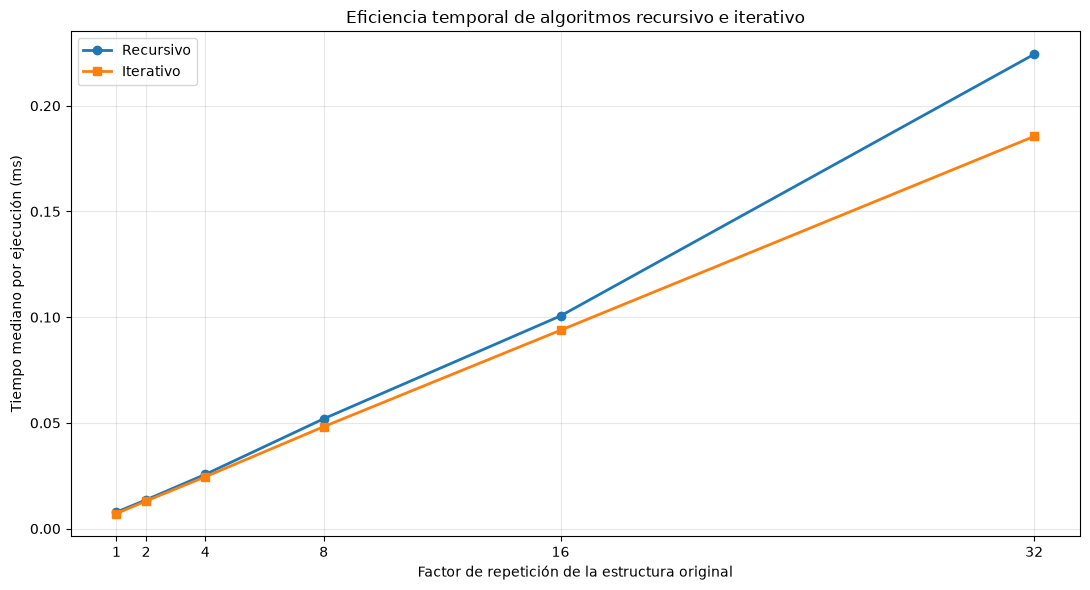

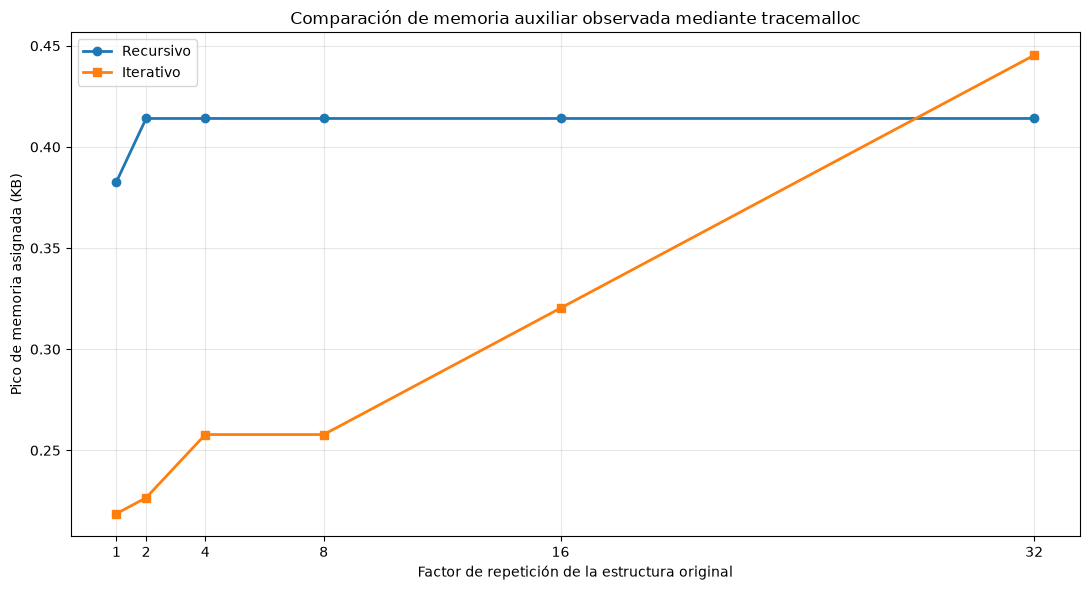

FASE 3 - VISUALIZACIÓN DE EFICIENCIA

VENTAJA TEMPORAL DE LA IMPLEMENTACIÓN ITERATIVA


algoritmo,factor_escala,RECURSIVO,ITERATIVO,ventaja_iterativa_pct
0,1,0.00784,0.00715,8.70
1,2,0.01363,0.01309,3.96
2,4,0.02566,0.02453,4.40
3,8,0.05197,0.04824,7.17
4,16,0.10061,0.09383,6.73
5,32,0.22433,0.18551,17.31



ARCHIVOS GENERADOS
F3_503_Figura_01_Eficiencia_Temporal.png
F3_503_Figura_02_Eficiencia_Memoria.png

[OK] Figura de eficiencia temporal generada.
[OK] Figura de memoria auxiliar generada.
[OK] Comparaciones verificadas.
[OK] Archivos guardados en F3/figuras.


In [7]:
# ==========================================================
# FASE 3 - APARTADO 5.3
# VISUALIZACIÓN DE EFICIENCIA ALGORÍTMICA
# PROYECTO MCDI500 - GRUPO 7
# ==========================================================

import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path
from IPython.display import display


# ==========================================================
# 1. CONFIGURAR CARPETA DE FIGURAS
# ==========================================================

CARPETA_FIGURAS_F3 = (
    Path(RAIZ_F3) / "F3" / "figuras"
)

CARPETA_FIGURAS_F3.mkdir(
    parents=True,
    exist_ok=True
)


# ==========================================================
# 2. VERIFICAR RESULTADOS DEL BENCHMARK
# ==========================================================

columnas_requeridas = [
    "algoritmo",
    "factor_escala",
    "asociaciones_procesadas",
    "tiempo_mediano_ms",
    "memoria_pico_kb"
]

faltantes = [
    columna
    for columna in columnas_requeridas
    if columna not in df_benchmark_f3.columns
]

if faltantes:
    raise ValueError(
        f"Faltan columnas del benchmark: {faltantes}"
    )

assert len(df_benchmark_f3) == 12

assert df_benchmark_f3[
    "tiempo_mediano_ms"
].gt(0).all()

assert df_benchmark_f3[
    "memoria_pico_kb"
].ge(0).all()


# ==========================================================
# 3. ORGANIZAR RESULTADOS PARA VISUALIZACIÓN
# ==========================================================

datos_tiempo = (
    df_benchmark_f3
    .pivot(
        index="factor_escala",
        columns="algoritmo",
        values="tiempo_mediano_ms"
    )
    .sort_index()
)

datos_memoria = (
    df_benchmark_f3
    .pivot(
        index="factor_escala",
        columns="algoritmo",
        values="memoria_pico_kb"
    )
    .sort_index()
)

factores = datos_tiempo.index.to_list()

assert len(factores) == 6


# ==========================================================
# 4. FIGURA 1 - COMPARACIÓN DE TIEMPOS
# ==========================================================

fig, ax = plt.subplots(
    figsize=(11, 6)
)

ax.plot(
    factores,
    datos_tiempo["RECURSIVO"],
    marker="o",
    linewidth=2,
    label="Recursivo"
)

ax.plot(
    factores,
    datos_tiempo["ITERATIVO"],
    marker="s",
    linewidth=2,
    label="Iterativo"
)

ax.set_title(
    "Eficiencia temporal de algoritmos "
    "recursivo e iterativo"
)

ax.set_xlabel(
    "Factor de repetición de la estructura original"
)

ax.set_ylabel(
    "Tiempo mediano por ejecución (ms)"
)

ax.set_xticks(factores)

ax.grid(
    alpha=0.3
)

ax.legend()

fig.tight_layout()

ruta_tiempo = (
    CARPETA_FIGURAS_F3
    / "F3_503_Figura_01_Eficiencia_Temporal.png"
)

fig.savefig(
    ruta_tiempo,
    dpi=220,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)


# ==========================================================
# 5. FIGURA 2 - COMPARACIÓN DE MEMORIA
# ==========================================================

fig, ax = plt.subplots(
    figsize=(11, 6)
)

ax.plot(
    factores,
    datos_memoria["RECURSIVO"],
    marker="o",
    linewidth=2,
    label="Recursivo"
)

ax.plot(
    factores,
    datos_memoria["ITERATIVO"],
    marker="s",
    linewidth=2,
    label="Iterativo"
)

ax.set_title(
    "Comparación de memoria auxiliar observada "
    "mediante tracemalloc"
)

ax.set_xlabel(
    "Factor de repetición de la estructura original"
)

ax.set_ylabel(
    "Pico de memoria asignada (KB)"
)

ax.set_xticks(factores)

ax.grid(
    alpha=0.3
)

ax.legend()

fig.tight_layout()

ruta_memoria = (
    CARPETA_FIGURAS_F3
    / "F3_503_Figura_02_Eficiencia_Memoria.png"
)

fig.savefig(
    ruta_memoria,
    dpi=220,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)


# ==========================================================
# 6. VERIFICAR ARCHIVOS GENERADOS
# ==========================================================

assert ruta_tiempo.exists(), (
    "No se generó la figura de eficiencia temporal."
)

assert ruta_memoria.exists(), (
    "No se generó la figura de memoria."
)


# ==========================================================
# 7. RESUMEN COMPARATIVO
# ==========================================================

resumen_visualizaciones = (
    datos_tiempo.reset_index()
)

resumen_visualizaciones[
    "ventaja_iterativa_pct"
] = (
    (
        resumen_visualizaciones["RECURSIVO"]
        - resumen_visualizaciones["ITERATIVO"]
    )
    / resumen_visualizaciones["RECURSIVO"]
    * 100
).round(2)


# ==========================================================
# 8. MOSTRAR RESULTADOS
# ==========================================================

print("=" * 65)
print("FASE 3 - VISUALIZACIÓN DE EFICIENCIA")
print("=" * 65)

print("\nVENTAJA TEMPORAL DE LA IMPLEMENTACIÓN ITERATIVA")

display(
    resumen_visualizaciones[
        [
            "factor_escala",
            "RECURSIVO",
            "ITERATIVO",
            "ventaja_iterativa_pct"
        ]
    ].round(5)
)

print("\nARCHIVOS GENERADOS")

print(ruta_tiempo.name)

print(ruta_memoria.name)

print("\n[OK] Figura de eficiencia temporal generada.")
print("[OK] Figura de memoria auxiliar generada.")
print("[OK] Comparaciones verificadas.")
print("[OK] Archivos guardados en F3/figuras.")